# Comparación de Clustering Jerárquico para Grafos

Este notebook compara los dos métodos implementados en `hierarchical_graph_clustering.py`:
1. **HierarchicalGraphClustering**: Enfoque exacto de complejidad cuadrática $O(N^2)$.
2. **ScalableHierarchicalGraphClustering**: Enfoque escalable (aproximado) mediante *Locality Sensitive Hashing (LSH)*.

In [2]:
import time
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

# Importar ambos modelos creados previamente
from hierarchical_graph_clustering import HierarchicalGraphClustering, ScalableHierarchicalGraphClustering

def plot_dendrogram(model, **kwargs):
    """
    Función auxiliar para graficar dendrogramas a partir de modelos 
    compatibles con la API de scikit-learn AgglomerativeClustering.
    """
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # nodo hoja
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    dendrogram(linkage_matrix, **kwargs)

### 1. Generación del Dataset Sintético
Se generarán 20 grafos en total: 10 grafos ciclo y 10 grafos aleatorios de Erdős-Rényi, para que los algoritmos puedan agruparlos de acuerdo a su similitud estructural medida por la Divergencia de Jensen-Shannon.

In [3]:
N_GRAPHS = 20
graphs = []

# Generar 10 grafos de ciclo
for i in range(10):
    # Nodos aleatorios entre 5 y 10
    graphs.append(nx.cycle_graph(np.random.randint(5, 11)))

# Generar 10 grafos Erdős-Rényi
for i in range(10):
    graphs.append(nx.erdos_renyi_graph(np.random.randint(5, 11), p=0.4))

print(f"Se generaron {len(graphs)} grafos para clustering.")

Se generaron 20 grafos para clustering.


### 2. Entrenamiento y Medición de Tiempo
A continuación incializamos ambos modelos. El modelo "escalable" incluye la semilla de LSH (hashings) para reducir el espacio de búsqueda cuadrática.

In [4]:
exact_model = HierarchicalGraphClustering(
    distance_threshold=0, 
    n_clusters=None, 
    compute_distances=True
)
scalable_model = ScalableHierarchicalGraphClustering(
    distance_threshold=0, 
    n_clusters=None, 
    compute_distances=True, 
    B=40, 
    N_projections=5, 
    epsilon=1e-5
)

# FIT EXACTO
start_exact = time.time()
exact_model.fit(graphs)
time_exact = time.time() - start_exact

# FIT ESCALABLE
start_scalable = time.time()
scalable_model.fit(graphs)
time_scalable = time.time() - start_scalable

print("---- RESULTADOS DE VELOCIDAD ----")
print(f"Tiempo Exacto (O(N^2)): {time_exact:.4f} segundos")
print(f"Tiempo Escalable (LSH): {time_scalable:.4f} segundos")

---- RESULTADOS DE VELOCIDAD ----
Tiempo Exacto (O(N^2)): 0.2460 segundos
Tiempo Escalable (LSH): 0.4867 segundos


### 3. Visualización y Comparación
A continuación mostramos el dendrograma que define la jerarquía generada por cada método y trazamos el avance de su función de calidad $q(C)$ iteración por iteración.

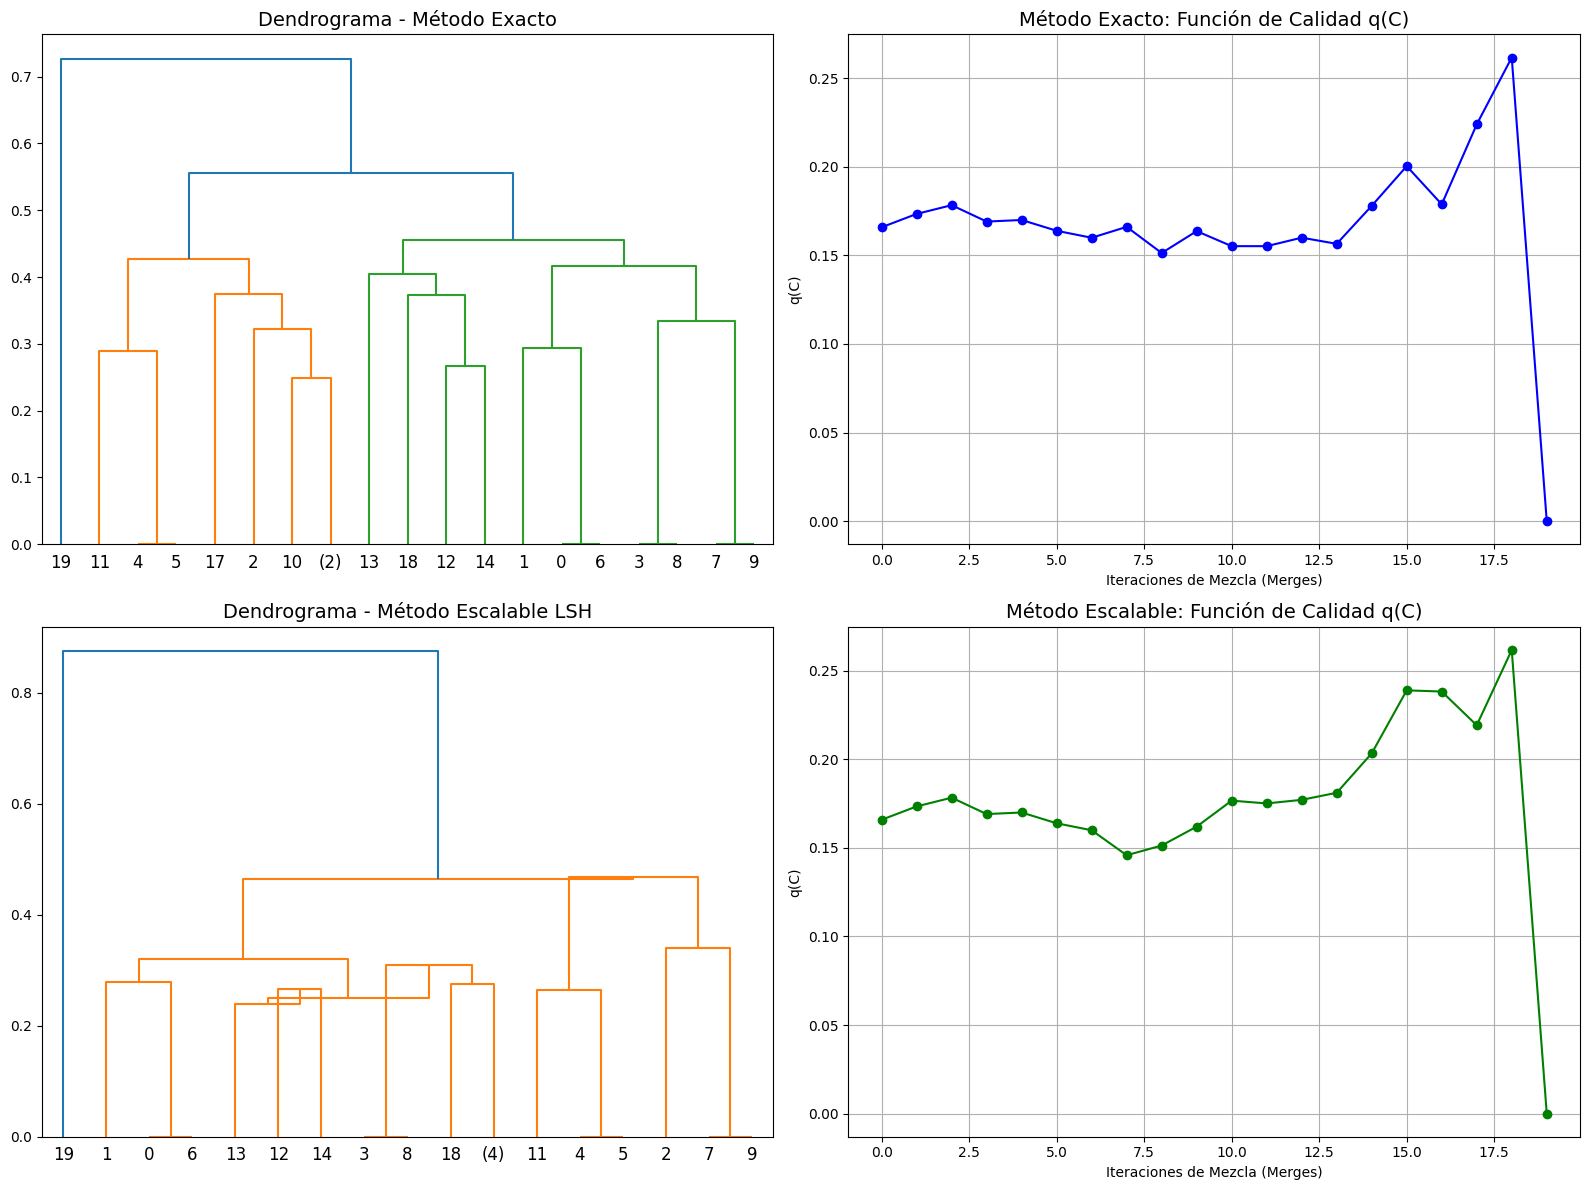

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ====== MODELO EXACTO ======
plt.subplot(2, 2, 1)
plt.title("Dendrograma - Método Exacto", fontsize=14)
plot_dendrogram(exact_model, truncate_mode="level", p=5)

plt.subplot(2, 2, 2)
plt.title("Método Exacto: Función de Calidad q(C)", fontsize=14)
plt.plot(range(len(exact_model.q_values_)), exact_model.q_values_, marker='o', color='b')
plt.xlabel("Iteraciones de Mezcla (Merges)")
plt.ylabel("q(C)")
plt.grid(True)

# ====== MODELO ESCALABLE (LSH) ======
plt.subplot(2, 2, 3)
plt.title("Dendrograma - Método Escalable LSH", fontsize=14)
if hasattr(scalable_model, 'children_') and len(scalable_model.children_) > 0:
    plot_dendrogram(scalable_model, truncate_mode="level", p=5)
else:
    plt.text(0.5, 0.5, 'No hubo convergencia / merges', ha='center')

plt.subplot(2, 2, 4)
plt.title("Método Escalable: Función de Calidad q(C)", fontsize=14)
if hasattr(scalable_model, 'q_values_'):
    plt.plot(range(len(scalable_model.q_values_)), scalable_model.q_values_, marker='o', color='g')
plt.xlabel("Iteraciones de Mezcla (Merges)")
plt.ylabel("q(C)")
plt.grid(True)

plt.tight_layout()
plt.show()

### 4. Prueba con Datos Reales: FAO Multiplex Trade Dataset
Cargamos la red comercial internacional Multiplex de la FAO. Cada capa (layer) del multiplex representa un producto agrícola distinto (trigo, maíz, vacas, etc), resultando en un grafo de países interconectados por su comercio.

Queremos agrupar estos productos en base a qué tan similar es la red logística/comercial entre ellos alrededor del mundo. Para evitar que el método exacto tarde demasiado en este ejemplo, limitaremos a procesar un subconjunto de productos (por ejemplo los primeros 60).

In [6]:
edges_file = "data/FAO_Multiplex_Trade/Dataset/fao_trade_multiplex.edges"
layers_file = "data/FAO_Multiplex_Trade/Dataset/fao_trade_layers.txt"

layer_labels = {}
with open(layers_file, 'r') as f:
    next(f) # skip header
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 2:
            layer_labels[int(parts[0])] = parts[1]

MAX_LAYERS = 60
fao_graphs = {i: nx.Graph() for i in range(1, MAX_LAYERS + 1)}

with open(edges_file, 'r') as f:
    for line in f:
        parts = line.strip().split()
        layer_id = int(parts[0])
        if layer_id <= MAX_LAYERS:
            u, v, w = int(parts[1]), int(parts[2]), float(parts[3])
            # Llenamos la red insertando aristas. 
            fao_graphs[layer_id].add_edge(u, v, weight=w)

graphs_fao = [fao_graphs[i] for i in range(1, MAX_LAYERS + 1) if fao_graphs[i].number_of_edges() > 0]
# Generamos un label real para los nodos de hojas si quisiéramos
labels_fao = [layer_labels.get(i, f"L{i}") for i in range(1, MAX_LAYERS + 1) if fao_graphs[i].number_of_edges() > 0]

print(f"Gráficos cargados y válidos: {len(graphs_fao)} capas seleccionadas.")

Gráficos cargados y válidos: 60 capas seleccionadas.


In [7]:
fao_exact = HierarchicalGraphClustering(distance_threshold=0, n_clusters=None, compute_distances=True)
fao_scalable = ScalableHierarchicalGraphClustering(distance_threshold=0, n_clusters=None, compute_distances=True, B=8, N_projections=5, epsilon=1e-5)

print("Iniciando clusterización Exacta O(N^2) en dataset FAO...")
sf_exact = time.time()
fao_exact.fit(graphs_fao)
tf_exact = time.time() - sf_exact

print("Iniciando clusterización Escalable (LSH) en dataset FAO...")
sf_sca = time.time()
fao_scalable.fit(graphs_fao)
tf_sca = time.time() - sf_sca

print("\n---- RESULTADOS SOBRE FAO TRADE MULTIPLEX ----")
print(f"Tiempo Exacto:   {tf_exact:.4f} segundos")
print(f"Tiempo Escalable: {tf_sca:.4f} segundos")

Iniciando clusterización Exacta O(N^2) en dataset FAO...
Iniciando clusterización Escalable (LSH) en dataset FAO...

---- RESULTADOS SOBRE FAO TRADE MULTIPLEX ----
Tiempo Exacto:   37.5829 segundos
Tiempo Escalable: 92.5421 segundos


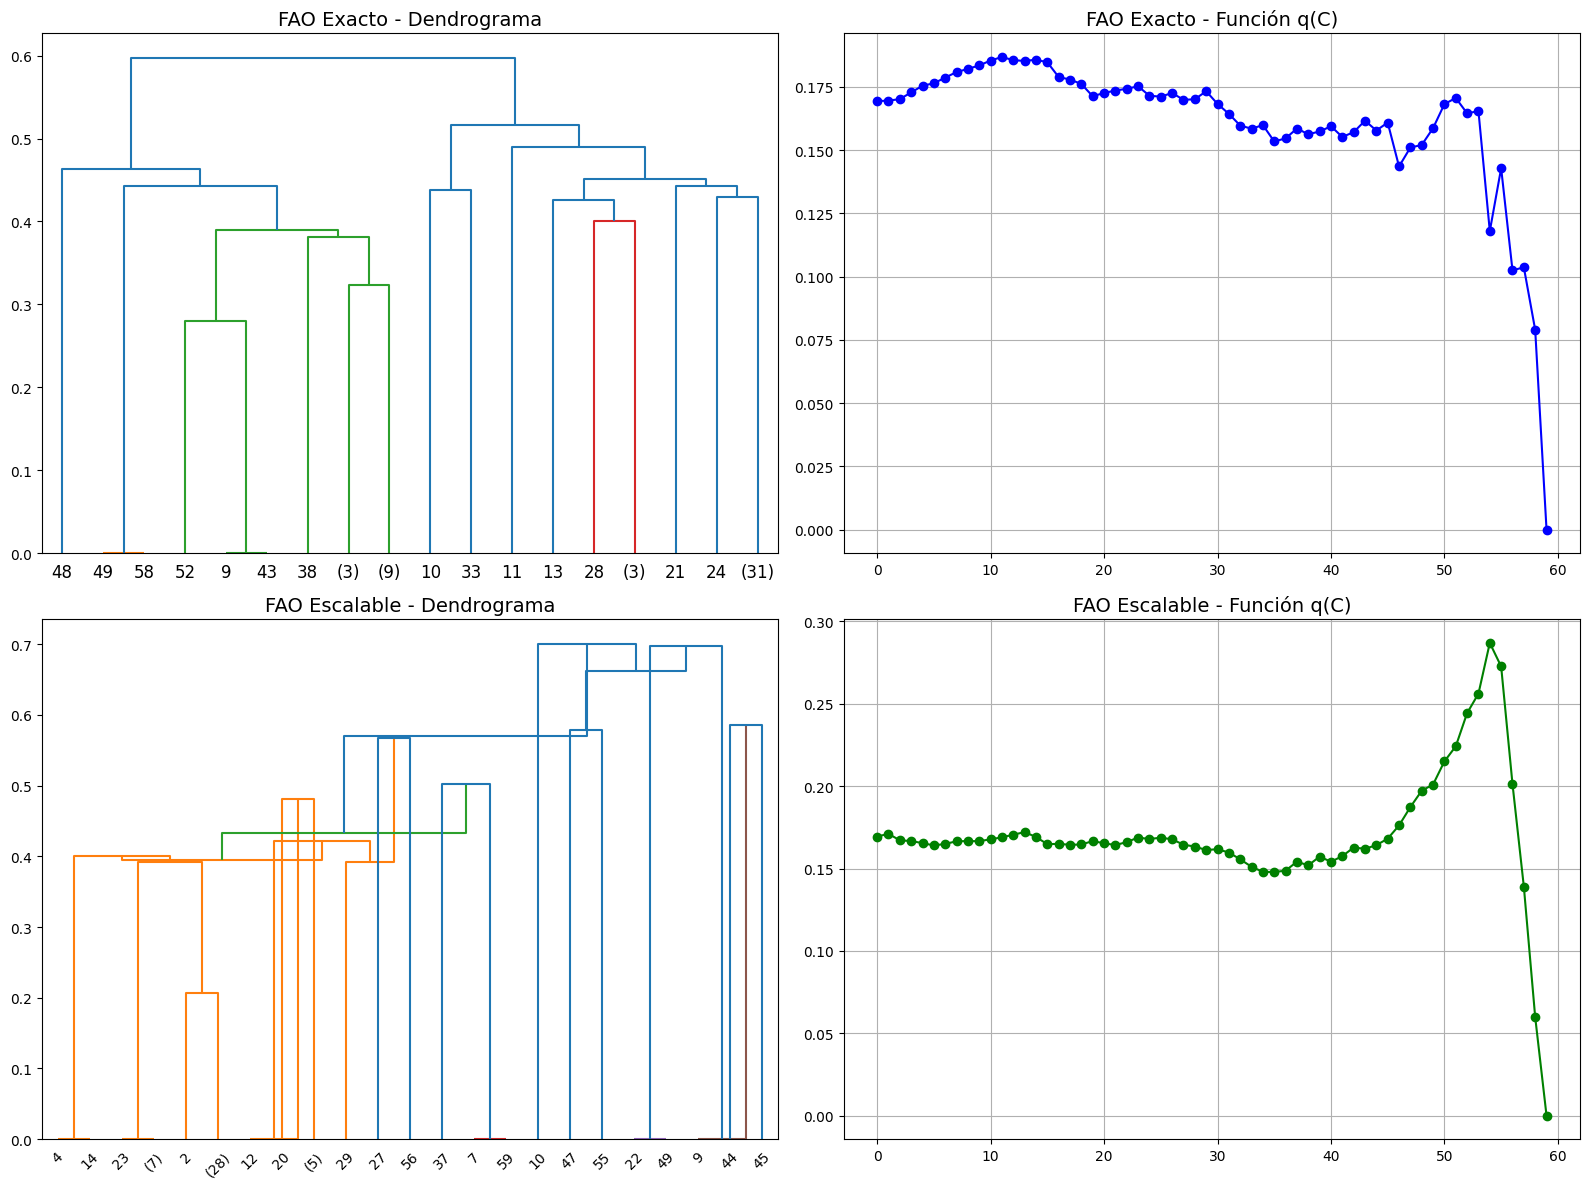

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

plt.subplot(2, 2, 1)
plt.title("FAO Exacto - Dendrograma", fontsize=14)
plot_dendrogram(fao_exact, truncate_mode="level", p=5)

plt.subplot(2, 2, 2)
plt.title("FAO Exacto - Función q(C)", fontsize=14)
plt.plot(range(len(fao_exact.q_values_)), fao_exact.q_values_, marker='o', color='b')
plt.grid(True)

plt.subplot(2, 2, 3)
plt.title("FAO Escalable - Dendrograma", fontsize=14)
if hasattr(fao_scalable, 'children_') and len(fao_scalable.children_) > 0:
    plot_dendrogram(fao_scalable, truncate_mode="level", p=5)
else:
    plt.text(0.5, 0.5, 'No hubo convergencia', ha='center')

plt.subplot(2, 2, 4)
plt.title("FAO Escalable - Función q(C)", fontsize=14)
if hasattr(fao_scalable, 'q_values_'):
    plt.plot(range(len(fao_scalable.q_values_)), fao_scalable.q_values_, marker='o', color='g')
plt.grid(True)

plt.tight_layout()
plt.show()